# Curve-based fusion detection: split roles and gate check

Prepares and checks the own approach (Branch B: a human-vs-ai window detector whose p(AI) curves feed a stacker together with Branch A, the tuned 3-class XLM-R from `hw3-encoder-tuning.ipynb`).

1. **Split roles**: which training texts train the detector and which train the stacker, with leakage checks. Written to `splits/curve_roles.csv` for the cluster jobs.
2. **Reference and error anatomy**: Branch A's validation score (R0) and where its human ↔ fusion errors are (length, domain).
3. **Twin boundaries**: for validation fusion texts with a human twin, the token where the copied human part ends.
4. **Gate texts**: the texts the gate job scores, written to `splits/gate_texts.csv`.

Runs on CPU. Only the tokenizer is used here; all models run on the cluster.

In [1]:
import os
import re
import sys
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from transformers import AutoTokenizer

sys.path.insert(0, str(Path("../cluster").resolve()))
from encoder.data import (GATE_CSV, LABELS, N_TRAIN_SAMPLE, ROLES_CSV, SEED, build_roles, load_data, prefix_key,
                          stratified_sample)

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"
BRANCH_A_DIR = Path("../outputs/branch_a/encoder")  # Kaggle output of hw3-encoder-tuning (probabilities only)
TOKENIZER = "xlm-roberta-base"                       # = FacebookAI/xlm-roberta-base, Branch A's tokenizer
BRANCH_A_TRAIN_WINDOWS = 104_407                     # "train_windows" in run_xlm-roberta-base.json

data = load_data(kagglehub.competition_download(COMPETITION))
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER)
pd.DataFrame({"texts": {name: len(df) for name, df in data.items()}}).T

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


,train,val,test
texts,245116,27236,25000


## 1. Split roles
- **detector**: the human and ai texts of the fixed 50k training sample (fusion excluded). Branch A was trained on the whole 50k sample.
- **stacker**: 30k texts from the training folds that are *not* in the 50k sample and whose 200-character prefix matches no sample text. The 50k sample was drawn without grouping, so without this twin guard a stacker fusion text could have its human twin among the detector's training texts. Drawn with the label × language shares of the training folds.
- **val** (fold 0) and **test** are only scored.

The checks below must all be 0. The last cell checks that the 50k sample rebuilt here is the one Branch A was trained on: it must give the same number of training windows as the Kaggle run.

In [2]:
def split_sets(roles, data):
    """Texts of each role, plus val and test."""
    train = data["train"]
    sets = {role: train[train["id"].isin(ids)].reset_index(drop=True) for role, ids in roles.groupby("role")["id"]}
    return {**sets, "val": data["val"], "test": data["test"]}


def leakage_checks(sets, train_sample):
    """Number of violations of each no-leakage rule (all must be 0)."""
    sample_ids, sample_prefixes = set(train_sample["id"]), set(prefix_key(train_sample["text"]))
    ids = {name: set(df["id"]) for name, df in sets.items()}
    pure_sample_ids = set(train_sample.loc[train_sample["label"] != "fusion", "id"])
    return pd.Series({
        "detector ∩ stacker": len(ids["detector"] & ids["stacker"]),
        "val ∩ (detector ∪ stacker)": len(ids["val"] & (ids["detector"] | ids["stacker"])),
        "stacker ∩ 50k sample": len(ids["stacker"] & sample_ids),
        "stacker prefix in 50k sample": prefix_key(sets["stacker"]["text"]).isin(sample_prefixes).sum(),
        "val prefix in 50k sample": prefix_key(sets["val"]["text"]).isin(sample_prefixes).sum(),
        "test prefix in 50k sample": prefix_key(sets["test"]["text"]).isin(sample_prefixes).sum(),
        "detector ≠ human/ai of 50k sample": len(ids["detector"] ^ pure_sample_ids),
    }, name="violations")


roles = build_roles(data["train"])
sets = split_sets(roles, data)
train_sample = stratified_sample(data["train"], N_TRAIN_SAMPLE)
checks = leakage_checks(sets, train_sample)
assert (checks == 0).all(), checks
checks.to_frame()

,violations
detector ∩ stacker,0
val ∩ (detector ∪ stacker),0
stacker ∩ 50k sample,0
stacker prefix in 50k sample,0
val prefix in 50k sample,0
test prefix in 50k sample,0
detector ≠ human/ai of 50k sample,0


In [3]:
def label_mix(sets):
    """Texts and label shares (%) of each labelled set."""
    rows = {name: {"texts": len(df), **(100 * df["label"].value_counts(normalize=True)).to_dict()}
            for name, df in sets.items() if "label" in df}
    return pd.DataFrame(rows).T[["texts", *LABELS]].fillna(0)


label_mix(sets).round(1)

,texts,human,ai,fusion
detector,34638.0,35.4,64.6,0.0
stacker,29999.0,24.5,44.8,30.7
val,27236.0,24.5,44.8,30.7


In [4]:
def branch_a_train_windows(texts, max_windows=4, batch_size=2_000):
    """Training windows Branch A got from these texts (512 tokens, overlap 128, at most 4 per text)."""
    total = 0
    for start in range(0, len(texts), batch_size):
        enc = tokenizer(list(texts[start:start + batch_size]), truncation=True, max_length=512, stride=128,
                        return_overflowing_tokens=True)
        total += np.minimum(np.bincount(enc["overflow_to_sample_mapping"]), max_windows).sum()
    return int(total)


n_windows = branch_a_train_windows(train_sample["text"].tolist())
assert n_windows == BRANCH_A_TRAIN_WINDOWS, n_windows
roles.to_csv(ROLES_CSV, index=False)
print(f"50k sample reproduces Branch A's {n_windows:,} training windows; wrote {ROLES_CSV.name} ({len(roles):,} rows)")

50k sample reproduces Branch A's 104,407 training windows; wrote curve_roles.csv (64,637 rows)


## 2. Reference (R0) and where Branch A fails
R0 is Branch A's validation macro-F1 from its saved probabilities (mean over 512-token windows, argmax). The tables show Branch A's error rate on human and fusion texts by token length, and where the human ↔ fusion errors are. "pair error" = a human text predicted as fusion or a fusion text predicted as human.

In [5]:
LENGTH_BINS = [0, 128, 256, 512, 1024, np.inf]
LENGTH_LABELS = ["<128", "128-256", "256-512", "512-1024", ">1024"]


def score(y_true, y_pred):
    """Macro-F1 and per-class F1."""
    per_class = f1_score(y_true, y_pred, labels=LABELS, average=None)
    return {"macro_f1": f1_score(y_true, y_pred, average="macro"),
            **{f"f1_{label}": f1 for label, f1 in zip(LABELS, per_class)}}


def with_branch_a(df, path):
    """df with Branch A's text probabilities, its argmax prediction and the error flags."""
    out = df.merge(pd.read_csv(path), on="id", validate="1:1")
    out["pred"] = np.array(LABELS)[out[LABELS].to_numpy().argmax(axis=1)]
    out["error"] = out["pred"] != out["label"]
    out["pair_error"] = out["error"] & out["label"].isin(["human", "fusion"]) & out["pred"].isin(["human", "fusion"])
    return out


def token_counts(texts):
    """Number of XLM-R tokens of each text (without special tokens)."""
    return [len(ids) for ids in tokenizer(list(texts), add_special_tokens=False, verbose=False)["input_ids"]]


val = with_branch_a(data["val"], BRANCH_A_DIR / "val_probs_xlm-roberta-base.csv")
val["n_tokens"] = token_counts(val["text"])
val["length"] = pd.cut(val["n_tokens"], LENGTH_BINS, labels=LENGTH_LABELS)
pd.DataFrame([score(val["label"], val["pred"])], index=["R0: Branch A, mean"]).round(4)

,macro_f1,f1_human,f1_ai,f1_fusion
"R0: Branch A, mean",0.902,0.8362,0.9901,0.8797


In [6]:
def error_rates(df, by):
    """Error and pair-error rates (%) of human and fusion texts per value of `by`."""
    pair = df[df["label"].isin(["human", "fusion"])]
    return (pair.groupby(["label", by], observed=True)
                .agg(texts=("error", "size"), error_pct=("error", "mean"), pair_error_pct=("pair_error", "mean"))
                .assign(error_pct=lambda d: 100 * d["error_pct"], pair_error_pct=lambda d: 100 * d["pair_error_pct"]))


error_rates(val, "length").round(1)

texts  error_pct  pair_error_pct
label  length                                    
fusion <128        507       17.2             9.1
       128-256     831       15.2            11.7
       256-512    2132        9.6             8.7
       512-1024   2938        5.0             3.9
       >1024      1960        3.8             3.2
human  <128        581       20.3            13.4
       128-256     599       23.9            22.2
       256-512    1417       16.7            16.1
       512-1024   2351       18.9            18.6
       >1024      1725       32.9            32.6

In [7]:
pair_errors = val[val["pair_error"]]
pd.concat({"by length": 100 * pair_errors["length"].value_counts(normalize=True).sort_index(),
           "by domain": 100 * pair_errors["domain"].value_counts(normalize=True)}).rename(
    f"% of the {len(pair_errors):,} human ↔ fusion errors").to_frame().round(1)

% of the 1,947 human ↔ fusion errors
by length <128                                                     6.4
          128-256                                                 11.8
          256-512                                                 21.2
          512-1024                                                28.5
          >1024                                                   32.2
by domain blog_authorship_corpus                                  24.8
          euro_court_cases                                        20.6
          bundestag                                               20.0
          student_essays                                          18.7
          house_of_commons                                         8.4
          cnn_news                                                 4.2
          arxiv_papers                                             2.4
          gutenberg                                                1.0

## 3. Twin boundaries
A fusion text with a human twin (same 200-character prefix, see EDA section 5) copies the twin word for word up to some point, then the AI-written part starts. The boundary is that point, as a token index in the fusion text and as a share of its length. Twins share a fold, so validation fusion texts find their twin within validation. Boundaries are only used to *evaluate* curves (gate criterion K1, xAI), never for fitting.

In [8]:
def boundary_char(fusion_text, human_text):
    """Character offset where the fusion text stops copying its human twin (end of the last copied word)."""
    copied = len(os.path.commonprefix([fusion_text.split(), human_text.split()]))
    word_ends = [m.end() for m in re.finditer(r"\S+", fusion_text)]
    return word_ends[copied - 1] if copied else 0


def twin_boundaries(fusion, humans):
    """Boundary token and share for fusion texts whose prefix matches exactly one human text in `humans`."""
    human_by_prefix = (humans.assign(prefix=prefix_key(humans["text"]))
                             .drop_duplicates("prefix", keep=False).set_index("prefix")["text"])
    fusion = fusion.assign(prefix=prefix_key(fusion["text"]))
    fusion = fusion[fusion["prefix"].isin(human_by_prefix.index)]
    chars = [boundary_char(f, human_by_prefix[p]) for f, p in zip(fusion["text"], fusion["prefix"])]
    enc = tokenizer(fusion["text"].tolist(), add_special_tokens=False, return_offsets_mapping=True, verbose=False)
    tokens = [int(np.searchsorted([start for start, _ in offsets], c)) for offsets, c in zip(enc["offset_mapping"], chars)]
    n_tokens = np.array([len(ids) for ids in enc["input_ids"]])
    return pd.DataFrame({"id": fusion["id"].to_numpy(), "boundary_char": chars, "boundary_tok": tokens,
                         "boundary_share": np.array(tokens) / n_tokens})


val_boundaries = twin_boundaries(val[val["label"] == "fusion"], val[val["label"] == "human"])
print(f"validation fusion texts with a twin boundary: {len(val_boundaries):,} of {(val['label'] == 'fusion').sum():,}")
val_boundaries[["boundary_tok", "boundary_share"]].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).T.round(2)

validation fusion texts with a twin boundary: 6,051 of 8,368


,0.10,0.25,0.50,0.75,0.90
boundary_tok,83.00,136.00,254.00,454.5,740.00
boundary_share,0.16,0.28,0.48,0.7,0.86


In [9]:
# Branch A misses more fusion texts when most of the text is copied human text.
missed = val.merge(val_boundaries, on="id").assign(missed=lambda d: d["pred"] != "fusion")
missed.groupby(pd.cut(missed["boundary_share"], [0, 0.25, 0.5, 0.75, 0.9, 1.0], include_lowest=True),
               observed=True)["missed"].agg(texts="size", missed_pct=lambda s: 100 * s.mean()).round(1)

,texts,missed_pct
boundary_share,,
"(-0.001, 0.25]",1269,5.4
"(0.25, 0.5]",1863,5.5
"(0.5, 0.75]",1728,5.6
"(0.75, 0.9]",785,10.1
"(0.9, 1.0]",406,23.6


## 4. Gate texts
The gate job scores two groups of texts:
- **val_plot**: 20 human and 20 fusion validation texts of at least 256 tokens (so a 128-token curve has several points), for the curve plots only. Each class is half Branch A errors, half correct. The fusion texts all have a known twin boundary.
- **stacker_slice**: 1,000 human, 1,000 fusion and 500 ai texts of the stacker set. The numeric gate criteria (K1–K3) are computed on these, not on validation.

In [10]:
PLOT_PER_GROUP = 10
PLOT_MIN_TOKENS = 256
SLICE_SIZES = {"human": 1_000, "fusion": 1_000, "ai": 500}


def plot_texts(val, boundaries):
    """10 texts each: human predicted fusion / human, fusion (with boundary) predicted human / fusion."""
    long = val[val["n_tokens"] >= PLOT_MIN_TOKENS]
    groups = {("human", "fusion"): long[long["label"] == "human"], ("human", "human"): long[long["label"] == "human"],
              ("fusion", "human"): long[(long["label"] == "fusion") & long["id"].isin(boundaries["id"])],
              ("fusion", "fusion"): long[(long["label"] == "fusion") & long["id"].isin(boundaries["id"])]}
    picks = [df[df["pred"] == pred].sample(PLOT_PER_GROUP, random_state=SEED) for (_, pred), df in groups.items()]
    return pd.concat(picks)


def stacker_slice(stacker):
    """Fixed random slice of the stacker set with SLICE_SIZES texts per label."""
    return pd.concat([stacker[stacker["label"] == label].sample(n, random_state=SEED) for label, n in SLICE_SIZES.items()])


gate = pd.concat([plot_texts(val, val_boundaries)[["id", "label", "pred"]].assign(set="val_plot"),
                  stacker_slice(sets["stacker"])[["id", "label"]].assign(set="stacker_slice")], ignore_index=True)
assert gate["id"].is_unique
gate[["id", "set"]].to_csv(GATE_CSV, index=False)
gate.groupby(["set", "label"]).size().rename("texts").to_frame()

texts
set           label        
stacker_slice ai        500
              fusion   1000
              human    1000
val_plot      fusion     20
              human      20

## 5. Gate results
Outputs of the gate job (`make -C cluster gate`, pulled to `cluster/results/<job>/`): a small human-vs-ai detector trained on 10k detector texts (128-token windows, 1 epoch), its p(AI) curves of the gate texts (a window every 32 tokens), and Branch A's probabilities of the same texts.

Criteria, fixed before looking (plan, section 1):

| | Test | Kill if |
|---|---|---|
| K1 | Localisation: AUC of p(AI) for windows after vs before the twin boundary (stacker-slice fusion texts) | < 0.70 |
| K2 | Human flatness: share of human texts with ≥ 2 consecutive high windows (p(AI) > 0.5) | > 25% |
| K3 | Added value: 5-fold CV human-vs-fusion macro-F1, Branch A + curve features minus Branch A alone | < 0.01 |
| Visual | Fusion curves look like human curves, or are uniformly mid-level | either |

Go if K1 ≥ 0.80 and K3 is clearly positive. K2 counts **non-overlapping** windows (every 4th window, one every 128 tokens): consecutive windows of the 32-token grid share 75% of their tokens, so two of them in a row would be nearly the same evidence.

In [11]:
import json

import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from encoder.curve_features import BASIC, CHANGEPOINT, CONTEXT, HIGH, curve_features, longest_run, subsample

GATE_JOB = "3016005"
GATE_DIR = Path("../cluster/results") / GATE_JOB
N_PARTS = 4  # one part file per GPU


def read_parts(pattern):
    """All per-GPU part files of one gate output, concatenated."""
    parts = sorted(GATE_DIR.glob(pattern))
    assert len(parts) == N_PARTS, f"{pattern}: {len(parts)} part files"
    return pd.concat([pd.read_csv(path) for path in parts], ignore_index=True)


curves = read_parts("curves_gate_128.part*.csv.gz").sort_values(["id", "position"], ignore_index=True)
gate_probs = read_parts("branch_a_probs_gate.part*.csv").set_index("id")
assert set(curves["id"]) == set(gate["id"]) == set(gate_probs.index), "gate outputs miss some texts"
detector_run = json.loads((GATE_DIR / "detector-gate.json").read_text())
pd.Series({"texts": curves["id"].nunique(), "windows": len(curves),
           "windows / text": len(curves) / curves["id"].nunique(),
           "detector training windows": detector_run["windows"]["128"],
           "detector train minutes": detector_run["train_minutes"]}).round(1).to_frame("gate run")

,gate run
texts,2540.0
windows,59506.0
windows / text,23.4
detector training windows,70815.0
detector train minutes,0.5


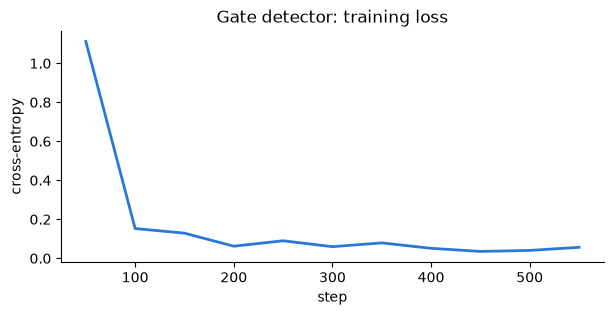

In [12]:
loss_log = pd.read_csv(GATE_DIR / "detector-gate_loss.csv")
ax = loss_log.plot(x="step", y="loss", legend=False, figsize=(7, 3), color="#2a78d6", linewidth=2)
ax.set(title="Gate detector: training loss", xlabel="step", ylabel="cross-entropy")
ax.spines[["top", "right"]].set_visible(False);

### Boundaries of the stacker-slice fusion texts
Same method as section 3. A stacker fusion text finds its human twin in the training folds (twins share a fold); by the twin guard, that twin is never one of the detector's training texts.

In [13]:
slice_texts = data["train"][data["train"]["id"].isin(gate.loc[gate["set"] == "stacker_slice", "id"])]
slice_boundaries = twin_boundaries(slice_texts[slice_texts["label"] == "fusion"],
                                   data["train"][data["train"]["label"] == "human"])
boundaries = pd.concat([val_boundaries, slice_boundaries]).set_index("id")
labels = pd.concat([data["train"], data["val"]]).set_index("id").loc[gate["id"], ["label", "domain"]]
print(f"stacker-slice fusion texts with a twin boundary: {len(slice_boundaries):,} of "
      f"{(slice_texts['label'] == 'fusion').sum():,}")

stacker-slice fusion texts with a twin boundary: 629 of 1,000


### K1: are windows after the boundary more AI-like than windows before it?
Windows of stacker-slice fusion texts with a known boundary are split into *before* (ends before the boundary), *after* (starts after it) and *straddle* (contains it). K1 compares *after* with *before*. As a reference, the same AUC for windows of pure ai vs pure human texts shows how well the detector separates the classes it was trained on.

In [14]:
def window_side(curves, boundaries):
    """Windows of texts with a known boundary, with side = before / straddle / after the boundary."""
    windows = curves.merge(boundaries[["boundary_tok"]], left_on="id", right_index=True)
    side = np.select([windows["tok_end"] <= windows["boundary_tok"], windows["tok_start"] >= windows["boundary_tok"]],
                     ["before", "after"], "straddle")
    return windows.assign(side=side)


def window_auc(windows, positive):
    """AUC of p(AI) for windows where `positive` is True vs the others, with window and text counts."""
    return {"windows": len(windows), "texts": windows["id"].nunique(),
            "AUC": roc_auc_score(positive, windows["p_ai"])}


slice_curves = curves[curves["id"].isin(slice_texts["id"])].join(labels["label"], on="id")
sides = window_side(slice_curves[slice_curves["label"] == "fusion"], boundaries)
clean_sides = sides[sides["side"] != "straddle"]
pure = slice_curves[slice_curves["label"].isin(["human", "ai"])]
auc_table = pd.DataFrame({
    "K1: fusion windows after vs before the boundary": window_auc(clean_sides, clean_sides["side"] == "after"),
    "reference: windows of ai vs human texts": window_auc(pure, pure["label"] == "ai"),
}).T
K1 = auc_table.iloc[0]["AUC"]
auc_table.round(3)

,windows,texts,AUC
K1: fusion windows after vs before the boundary,12221.0,596.0,0.721
reference: windows of ai vs human texts,33935.0,1500.0,0.999


In [15]:
# Where do the window groups sit? If "after" is close to "ai", the AI part of fusion looks like pure ai to the detector.
window_groups = pd.concat([
    sides[["p_ai"]].assign(group="fusion: " + sides["side"]),
    pure[["p_ai"]].assign(group=pure["label"] + " texts"),
])
GROUP_ORDER = ["human texts", "fusion: before", "fusion: straddle", "fusion: after", "ai texts"]
(window_groups.groupby("group")["p_ai"]
              .agg(windows="size", mean="mean", median="median", high_pct=lambda p: 100 * (p > HIGH).mean())
              .loc[GROUP_ORDER].round(3))

,windows,mean,median,high_pct
group,,,,
human texts,23420,0.032,0.000,3.134
fusion: before,5531,0.028,0.000,2.730
fusion: straddle,2234,0.465,0.237,46.509
fusion: after,6690,0.387,0.001,38.625
ai texts,10515,0.998,1.000,99.838


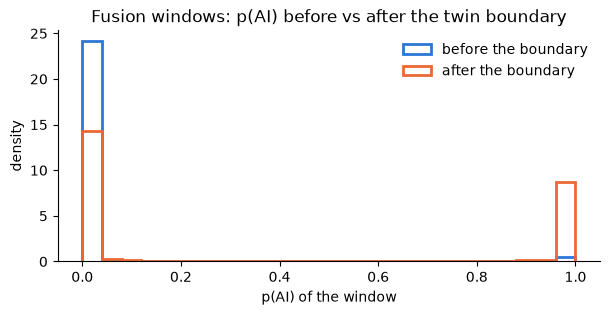

In [16]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, 1, 26)
for side, color in [("before", "#2a78d6"), ("after", "#eb6834")]:
    ax.hist(clean_sides.loc[clean_sides["side"] == side, "p_ai"], bins=bins, density=True, histtype="step",
            linewidth=2, color=color, label=f"{side} the boundary")
ax.set(title="Fusion windows: p(AI) before vs after the twin boundary", xlabel="p(AI) of the window", ylabel="density")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False);

### K2: do human curves stay low?
For each stacker-slice text with at least two non-overlapping windows: does it contain a run of ≥ 2 consecutive non-overlapping windows with p(AI) > 0.5? K2 is the human share; fusion and ai are shown for comparison (fusion should be much higher than human).

In [17]:
MIN_RUN = 2
NON_OVERLAP = 4  # every 4th window of the 32-token grid = one 128-token window every 128 tokens


def longest_high_run(p_ai):
    """Number of windows in the longest run of consecutive windows with p(AI) > HIGH."""
    start, end = longest_run(p_ai.to_numpy() > HIGH)
    return end - start


def high_run_share(curves, labels):
    """Per label: texts with >= MIN_RUN non-overlapping windows, and % of them with a high run of that length."""
    coarse = subsample(curves, NON_OVERLAP)
    runs = coarse.groupby("id").agg(windows=("p_ai", "size"), longest=("p_ai", longest_high_run))
    runs = runs[runs["windows"] >= MIN_RUN].join(labels["label"])
    return runs.groupby("label").agg(texts=("longest", "size"),
                                     high_run_pct=("longest", lambda n: 100 * (n >= MIN_RUN).mean()))


k2_table = high_run_share(slice_curves, labels).loc[["human", "fusion", "ai"]]
K2 = k2_table.loc["human", "high_run_pct"]
k2_table.round(1)

,texts,high_run_pct
label,,
human,912,2.7
fusion,926,50.2
ai,465,99.8


### K3: do curve features add to Branch A for human vs fusion?
On the stacker-slice human and fusion texts: 5-fold cross-validated logistic regression (scaled, balanced classes), out-of-fold macro-F1 over the two classes. Branch A enters as its log-probabilities. Everything is fitted inside the CV folds of the slice; validation is not used.

In [18]:
BRANCH_A_FEATURES = [f"logp_{label}" for label in LABELS]
FEATURE_SETS = {
    "Branch A": BRANCH_A_FEATURES,
    "curves": BASIC + CHANGEPOINT + CONTEXT,
    "Branch A + basic curve features": BRANCH_A_FEATURES + BASIC + CONTEXT,
    "Branch A + all curve features": BRANCH_A_FEATURES + BASIC + CHANGEPOINT + CONTEXT,
}
CV_FOLDS = 5


def pair_features(curves, probs, ids):
    """Curve features and Branch A log-probabilities of the texts in ids."""
    features = curve_features(curves[curves["id"].isin(ids)])
    log_probs = np.log(probs.loc[features.index, LABELS].clip(lower=1e-6)).add_prefix("logp_")
    return features.join(log_probs)


def cv_macro_f1(X, y, columns):
    """Out-of-fold macro-F1 of a scaled, class-balanced logistic regression on the given columns."""
    model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5_000))
    pred = cross_val_predict(model, X[columns], y, cv=StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED))
    return f1_score(y, pred, average="macro")


pair_ids = labels.index[labels["label"].isin(["human", "fusion"]) & labels.index.isin(slice_texts["id"])]
X_pair = pair_features(curves, gate_probs, pair_ids)
y_pair = labels.loc[X_pair.index, "label"]
k3_table = pd.Series({name: cv_macro_f1(X_pair, y_pair, columns) for name, columns in FEATURE_SETS.items()},
                     name="CV macro-F1, human vs fusion").to_frame()
K3 = k3_table.loc["Branch A + all curve features"].item() - k3_table.loc["Branch A"].item()
k3_table.round(4)

,"CV macro-F1, human vs fusion"
Branch A,0.8844
curves,0.8280
Branch A + basic curve features,0.9059
Branch A + all curve features,0.9074


In [19]:
def single_feature_auc(X, y):
    """AUC of each feature alone for fusion vs human (0.5 = useless, far from 0.5 = useful)."""
    is_fusion = (y == "fusion").to_numpy()
    return pd.Series({column: roc_auc_score(is_fusion, X[column]) for column in X.columns},
                     name="AUC fusion vs human").sort_values(key=lambda auc: -abs(auc - 0.5))


single_feature_auc(X_pair, y_pair).round(3).to_frame()

,AUC fusion vs human
logp_human,0.054
logp_fusion,0.940
mean,0.889
max,0.881
frac_high,0.848
longest_high_share,0.848
std,0.835
mean_abs_diff,0.797
n_switches,0.765
tail_mean,0.747


### The curves
40 validation texts (section 4): each row is one group of 10. Line: the detector's p(AI) per window, plotted at the window centre as a share of the text length. Dotted: p(AI) = 0.5. Dashed (fusion only): the true boundary, where the copied human text ends. Panel titles: domain, length in tokens, Branch A's p(fusion).

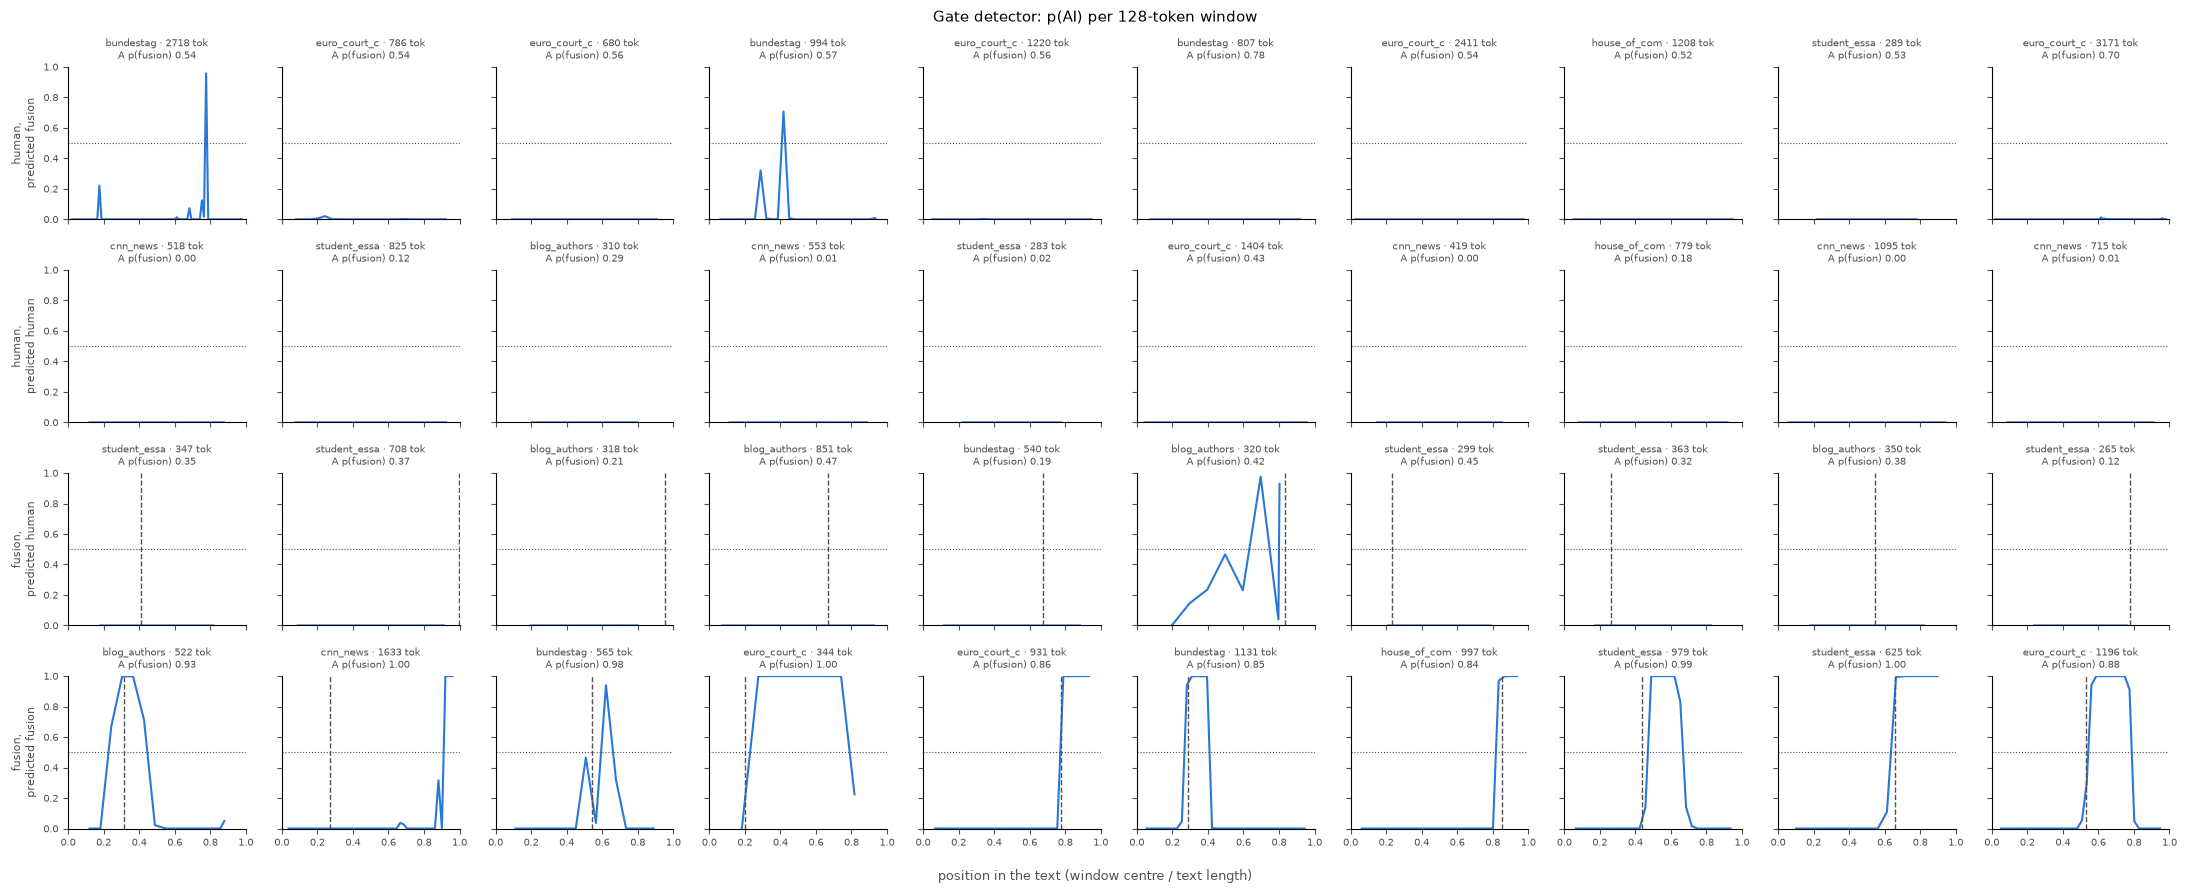

In [20]:
PLOT_ROWS = [("human", "fusion", "human,\npredicted fusion"), ("human", "human", "human,\npredicted human"),
             ("fusion", "human", "fusion,\npredicted human"), ("fusion", "fusion", "fusion,\npredicted fusion")]
CURVE_COLOR, REFERENCE_COLOR, TEXT_COLOR = "#2a78d6", "#52514e", "#52514e"


def plot_gate_curves(curves, plot_texts, boundaries, probs):
    """4 x 10 small multiples of p(AI) curves, one row per (label, Branch A prediction) group."""
    fig, axes = plt.subplots(len(PLOT_ROWS), PLOT_PER_GROUP, figsize=(22, 9), sharex=True, sharey=True)
    for row, (label, pred, row_title) in enumerate(PLOT_ROWS):
        group = plot_texts[(plot_texts["label"] == label) & (plot_texts["pred"] == pred)]
        for ax, text in zip(axes[row], group.itertuples()):
            windows = curves[curves["id"] == text.id]
            centre = (windows["tok_start"] + windows["tok_end"]) / 2 / windows["n_tokens"]
            ax.plot(centre, windows["p_ai"], color=CURVE_COLOR, linewidth=1.5)
            ax.axhline(HIGH, color=REFERENCE_COLOR, linewidth=0.8, linestyle=":")
            if text.id in boundaries.index:
                ax.axvline(boundaries.loc[text.id, "boundary_share"], color=REFERENCE_COLOR, linewidth=1, linestyle="--")
            ax.set_title(f"{text.domain[:12]} · {text.n_tokens} tok\nA p(fusion) {probs.loc[text.id, 'fusion']:.2f}",
                         fontsize=7, color=TEXT_COLOR)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(labelsize=7, colors=TEXT_COLOR)
        axes[row, 0].set_ylabel(row_title, fontsize=8, color=TEXT_COLOR)
    axes[0, 0].set_ylim(0, 1)
    axes[0, 0].set_xlim(0, 1)
    fig.supxlabel("position in the text (window centre / text length)", fontsize=9, color=TEXT_COLOR)
    fig.suptitle("Gate detector: p(AI) per 128-token window", fontsize=11)
    fig.tight_layout()
    return fig


plot_texts_info = gate[gate["set"] == "val_plot"].merge(val[["id", "domain", "n_tokens"]], on="id")
plot_gate_curves(curves, plot_texts_info, boundaries, gate_probs);

### Gate summary
The numbers against the fixed criteria. The visual criterion is judged from the figure above.

In [21]:
gate_summary = pd.DataFrame([
    {"criterion": "K1: localisation AUC", "value": K1, "kill if": "< 0.70", "go if": "≥ 0.80", "passes": K1 >= 0.70},
    {"criterion": "K2: human texts with a high run (%)", "value": K2, "kill if": "> 25", "go if": "≤ 25",
     "passes": K2 <= 25},
    {"criterion": "K3: CV macro-F1 gain over Branch A", "value": K3, "kill if": "< 0.01", "go if": "clearly > 0",
     "passes": K3 >= 0.01},
]).set_index("criterion")
gate_summary.round(3)

,value,kill if,go if,passes
criterion,,,,
K1: localisation AUC,0.721,< 0.70,≥ 0.80,True
K2: human texts with a high run (%),2.741,> 25,≤ 25,True
K3: CV macro-F1 gain over Branch A,0.023,< 0.01,clearly > 0,True
